<a href="https://colab.research.google.com/github/jfwelias-tech/portfolio-dados/blob/master/Projeto_04_Titanic_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Fonte dos dados

A base reúne 891 registros de passageiros e como material de estudo. [Acessar a cópia do CSV usada neste projeto](https://drive.google.com/file/d/1YBOVngIdbdPAarnzADnPwTjNZuvBQinO/view?usp=sharing).

Para reproduzir a análise, abra o notebook no Colab e execute as células em ordem. A primeira célula de código carrega o CSV pelo link público.

In [1]:
import pandas as pd

file_id = "1YBOVngIdbdPAarnzADnPwTjNZuvBQinO"
url_csv = f"https://drive.google.com/uc?export=download&id={file_id}"

dados_originais = pd.read_csv(url_csv)
dados = dados_originais.copy()

dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [2]:
dados["Survived"].value_counts()

,count
Survived,
0,549
1,342


In [3]:
# Calcula a porcentagem de cada resultado
dados["Survived"].value_counts(normalize=True) * 100

,proportion
Survived,
0,61.616162
1,38.383838


In [4]:
# Porcentagem de sobreviventes por sexo registrado na base
dados.groupby("Sex")["Survived"].mean() * 100

,Survived
Sex,
female,74.203822
male,18.890815


In [5]:
# Porcentagem de sobreviventes em cada classe
dados.groupby("Pclass")["Survived"].mean() * 100

,Survived
Pclass,
1,62.962963
2,47.282609
3,24.236253


In [6]:
# Taxa de sobrevivência por sexo e classe
dados.groupby(["Sex", "Pclass"])["Survived"].mean() * 100

Sex     Pclass
female  1         96.808511
        2         92.105263
        3         50.000000
male    1         36.885246
        2         15.740741
        3         13.544669
Name: Survived, dtype: float64

In [7]:
# Quantidade de passageiros em cada combinação de sexo e classe
dados.groupby(["Sex", "Pclass"]).size()

Sex     Pclass
female  1          94
        2          76
        3         144
male    1         122
        2         108
        3         347
dtype: int64

In [8]:
# Resumo das idades disponíveis
dados["Age"].describe()

,Age
count,714.000000
mean,29.699118
std,14.526497
min,0.420000
25%,20.125000
50%,28.000000
75%,38.000000
max,80.000000


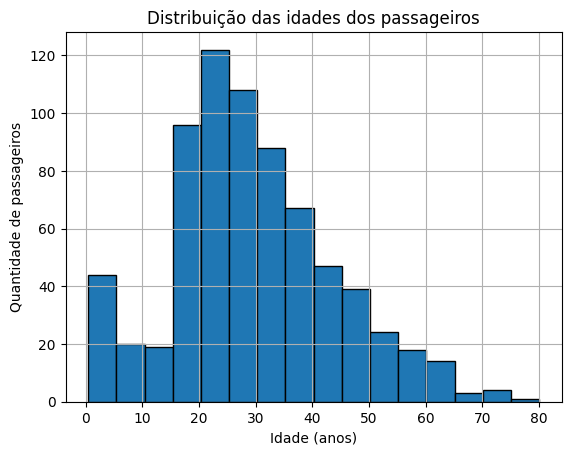

In [9]:
import matplotlib.pyplot as plt

dados["Age"].hist(bins=16, edgecolor="black")

plt.title("Distribuição das idades dos passageiros")
plt.xlabel("Idade (anos)")
plt.ylabel("Quantidade de passageiros")
plt.show()

In [10]:
# Resume as idades separadamente para não sobreviventes e sobreviventes
dados.groupby("Survived")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,424.0,30.626179,14.172110,1.00,21.0,28.0,39.0,74.0
1,290.0,28.343690,14.950952,0.42,19.0,28.0,36.0,80.0


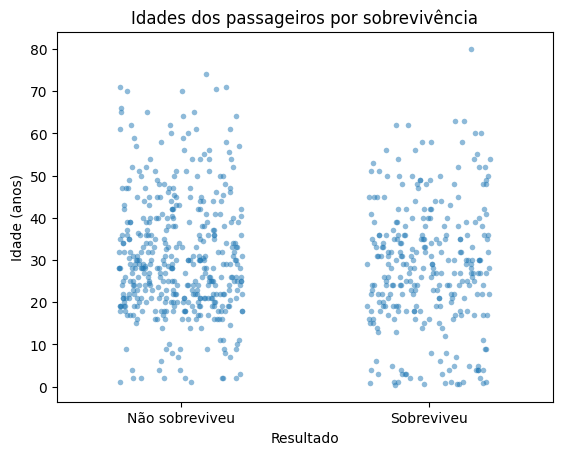

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.stripplot(
    data=dados,
    x="Survived",
    y="Age",
    jitter=0.25,
    alpha=0.5,
    size=4
)

plt.xticks([0, 1], ["Não sobreviveu", "Sobreviveu"])
plt.xlabel("Resultado")
plt.ylabel("Idade (anos)")
plt.title("Idades dos passageiros por sobrevivência")
plt.show()

In [12]:
# Seleciona passageiros com idade conhecida, sem alterar a tabela original
idades_conhecidas = dados.dropna(subset=["Age"]).copy()

# Identifica quem tinha menos de 12 anos
idades_conhecidas["Menor_de_12"] = idades_conhecidas["Age"] < 12

# Calcula a taxa de sobrevivência em cada grupo
idades_conhecidas.groupby("Menor_de_12")["Survived"].mean() * 100

,Survived
Menor_de_12,
False,38.854489
True,57.352941


Entre os passageiros com idade conhecida, 57,4% dos menores de 12 anos sobreviveram, contra 38,9% daqueles com 12 anos ou mais. O corte de 12 anos foi adotado para exploração e não representa uma regra do modelo.

In [13]:
idades_conhecidas.groupby("Menor_de_12")["Survived"].agg(
    passageiros="size",
    sobreviventes="sum"
)

,passageiros,sobreviventes
Menor_de_12,,
False,646,251
True,68,39


Faixa de idade -	Passageiros	Sobreviventes	Taxa
Menos de 12 anos:	68	| 39	| 57,4%
12 anos ou mais:	646 |	251	| 38,9%

In [14]:
# Características que o modelo receberá para fazer a previsão
X = dados[["Pclass", "Sex", "Age"]].copy()

# Resultado que queremos prever
y = dados["Survived"].copy()

X.head()

,Pclass,Sex,Age
0,3,male,22.0
1,1,female,38.0
2,3,female,26.0
3,1,female,35.0
4,3,male,35.0


In [15]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Passageiros no treino:", len(X_treino))
print("Passageiros no teste:", len(X_teste))

Passageiros no treino: 712
Passageiros no teste: 179


In [16]:
# Calcula a mediana usando apenas as idades do treino
mediana_idade = X_treino["Age"].median()

print("Mediana da idade no treino:", mediana_idade)
print("Idades ausentes no treino:", X_treino["Age"].isna().sum())

Mediana da idade no treino: 28.5
Idades ausentes no treino: 137


In [17]:
# Cria cópias para preparar os dados
X_treino = X_treino.copy()
X_teste = X_teste.copy()

# Aplica a mesma mediana do treino nos dois conjuntos
X_treino["Age"] = X_treino["Age"].fillna(mediana_idade)
X_teste["Age"] = X_teste["Age"].fillna(mediana_idade)

# Confere se restaram idades ausentes
print("Ausentes no treino:", X_treino["Age"].isna().sum())
print("Ausentes no teste:", X_teste["Age"].isna().sum())

Ausentes no treino: 0
Ausentes no teste: 0


A mediana do treino é 28,5 anos, diferente dos 28 anos calculados na base completa. É esse valor do treino que vamos usar para preencher as ausências.

In [18]:
# Define a mesma codificação para treino e teste
mapa_sexo = {"female": 0, "male": 1}

# Cria versões numéricas, preservando as tabelas anteriores
X_treino_numerico = X_treino.copy()
X_teste_numerico = X_teste.copy()

X_treino_numerico["Sex"] = X_treino["Sex"].map(mapa_sexo)
X_teste_numerico["Sex"] = X_teste["Sex"].map(mapa_sexo)

X_treino_numerico.head()

,Pclass,Sex,Age
692,3,1,28.5
481,2,1,28.5
527,1,1,28.5
855,3,0,18.0
801,2,0,31.0


In [19]:
from sklearn.linear_model import LogisticRegression

# Cria o modelo
modelo = LogisticRegression(max_iter=1000)

# Aprende a relação entre as características e os resultados do treino
modelo.fit(X_treino_numerico, y_treino)

LogisticRegression(max_iter=1000)

Pronto! Nosso primeiro modelo está treinado!

In [20]:
from sklearn.metrics import accuracy_score

# Prevê os resultados sem consultar as respostas do teste
previsoes = modelo.predict(X_teste_numerico)

# Compara as previsões com os resultados reais
acuracia = accuracy_score(y_teste, previsoes)

print(f"Acurácia no teste: {acuracia:.1%}")

Acurácia no teste: 78.2%


In [21]:
# Identifica o resultado mais frequente no treino
classe_majoritaria = y_treino.mode()[0]

# Repete essa resposta para todos os passageiros do teste
previsoes_baseline = [classe_majoritaria] * len(y_teste)

acuracia_baseline = accuracy_score(y_teste, previsoes_baseline)

print(f"Acurácia do baseline: {acuracia_baseline:.1%}")
print(f"Acurácia da Regressão Logística: {acuracia:.1%}")

Acurácia do baseline: 61.5%
Acurácia da Regressão Logística: 78.2%


In [22]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(y_teste, previsoes, labels=[0, 1])

pd.DataFrame(
    matriz,
    index=["Real: não sobreviveu", "Real: sobreviveu"],
    columns=["Previsto: não sobreviveu", "Previsto: sobreviveu"]
)

,Previsto: não sobreviveu,Previsto: sobreviveu
Real: não sobreviveu,92,18
Real: sobreviveu,21,48


In [23]:
from sklearn.metrics import precision_score, recall_score

precisao = precision_score(y_teste, previsoes)
recall = recall_score(y_teste, previsoes)

print(f"Precisão para sobrevivência: {precisao:.1%}")
print(f"Recall para sobrevivência: {recall:.1%}")

Precisão para sobrevivência: 72.7%
Recall para sobrevivência: 69.6%


In [24]:
# Personagem: mulher de 25 anos, viajando na 2ª classe
personagem = pd.DataFrame({
    "Pclass": [2],
    "Sex": [0],  # Mesma codificação do treino: female = 0
    "Age": [25]
})

# Calcula as probabilidades estimadas para as duas classes
probabilidades = modelo.predict_proba(personagem)

print("Ordem das classes:", modelo.classes_)
print("Probabilidades:", probabilidades)

Ordem das classes: [0 1]
Probabilidades: [[0.18429952 0.81570048]]


In [25]:
# Primeiro personagem (linha 0), sobrevivência (coluna 1)
chance_sobrevivencia = probabilidades[0, 1]

print(f"Chance estimada de sobrevivência: {chance_sobrevivencia:.1%}")

Chance estimada de sobrevivência: 81.6%


In [26]:
personagem_homem = pd.DataFrame({
    "Pclass": [2],
    "Sex": [1],
    "Age": [25]
})

chance_homem = modelo.predict_proba(personagem_homem)[0, 1]

print(f"Chance estimada de sobrevivência: {chance_homem:.1%}")

Chance estimada de sobrevivência: 26.2%


Mantendo 25 anos e 2ª classe, obtivemos:
Personagem	Probabilidade estimada de sobrevivência
Mulher	81,6%
Homem	26,2%


A diferença é de 55,4 pontos percentuais. O modelo aprendeu uma associação entre o sexo registrado e a sobrevivência. Essa comparação mostra o comportamento do modelo; não demonstra, sozinha, uma relação causal.

In [27]:
personagens = pd.DataFrame({
    "Pclass": [1, 2, 3],
    "Sex": [1, 1, 1],
    "Age": [25, 25, 25]
})

# Seleciona a probabilidade de sobrevivência de todas as linhas
chances = modelo.predict_proba(personagens)[:, 1]

resultado = personagens.copy()
resultado["Sobrevivência estimada (%)"] = (chances * 100).round(1)

resultado

,Pclass,Sex,Age,Sobrevivência estimada (%)
0,1,1,25,53.1
1,2,1,25,26.2
2,3,1,25,10.1


In [28]:
# Acrescenta a classificação dos três personagens
resultado["Previsão"] = modelo.predict(personagens)

resultado

,Pclass,Sex,Age,Sobrevivência estimada (%),Previsão
0,1,1,25,53.1,1
1,2,1,25,26.2,0
2,3,1,25,10.1,0


In [29]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Recarrega os dados originais
dados = dados_originais.copy()

X = dados[["Pclass", "Sex", "Age"]].copy()
y = dados["Survived"].copy()

# Reproduz a mesma divisão anterior
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Passageiros no treino:", len(X_treino))
print("Idades ausentes no treino:", X_treino["Age"].isna().sum())

Passageiros no treino: 712
Idades ausentes no treino: 137


In [30]:
from sklearn.impute import SimpleImputer

# Define a estratégia de preenchimento
preenchedor_idade = SimpleImputer(strategy="median")

# Aprende a mediana apenas com o treino
preenchedor_idade.fit(X_treino[["Age"]])

print("Mediana aprendida:", preenchedor_idade.statistics_[0])

Mediana aprendida: 28.5


In [31]:
# Aplica a mediana aprendida, sem recalculá-la
idades_treino_preenchidas = preenchedor_idade.transform(X_treino[["Age"]])
idades_teste_preenchidas = preenchedor_idade.transform(X_teste[["Age"]])

# Compara as primeiras idades do treino
comparacao = pd.DataFrame({
    "Idade original": X_treino["Age"].to_numpy(),
    "Idade preenchida": idades_treino_preenchidas[:, 0]
})

comparacao.head()

,Idade original,Idade preenchida
0,NaN,28.5
1,NaN,28.5
2,NaN,28.5
3,18.0,18.0
4,31.0,31.0


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preparacao = ColumnTransformer(
    transformers=[
        ("idade", SimpleImputer(strategy="median"), ["Age"]),
        ("sexo", OneHotEncoder(drop="if_binary"), ["Sex"]),
        ("classe", "passthrough", ["Pclass"])
    ]
)

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipeline_logistica = Pipeline([
    ("preparacao", preparacao),
    ("modelo", LogisticRegression(max_iter=1000))
])

# Recebe os dados originais do treino, ainda com textos e ausências
pipeline_logistica.fit(X_treino, y_treino)

Pipeline(steps=[('preparacao',
                 ColumnTransformer(transformers=[('idade',
                                                  SimpleImputer(strategy='median'),
                                                  ['Age']),
                                                 ('sexo',
                                                  OneHotEncoder(drop='if_binary'),
                                                  ['Sex']),
                                                 ('classe', 'passthrough',
                                                  ['Pclass'])])),
                ('modelo', LogisticRegression(max_iter=1000))])

In [34]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Mantém proporções semelhantes de sobreviventes em cada grupo
validacao = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Avalia cinco cópias do pipeline, treinadas separadamente
acuracias = cross_val_score(
    pipeline_logistica,
    X_treino,
    y_treino,
    cv=validacao,
    scoring="accuracy"
)

print("Acurácias por rodada (%):", (acuracias * 100).round(1))
print(f"Acurácia média: {acuracias.mean():.1%}")

Acurácias por rodada (%): [79.  76.2 80.3 76.1 82.4]
Acurácia média: 78.8%


In [35]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

pipeline_arvore = Pipeline([
    ("preparacao", clone(preparacao)),
    ("modelo", DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

# Usa exatamente as mesmas divisões da Regressão Logística
acuracias_arvore = cross_val_score(
    pipeline_arvore,
    X_treino,
    y_treino,
    cv=validacao,
    scoring="accuracy"
)

print("Acurácias da árvore (%):", (acuracias_arvore * 100).round(1))
print(f"Média da árvore: {acuracias_arvore.mean():.1%}")
print(f"Média da Regressão Logística: {acuracias.mean():.1%}")

Acurácias da árvore (%): [81.1 79.  83.8 80.3 81.7]
Média da árvore: 81.2%
Média da Regressão Logística: 78.8%


**A árvore teve maior acurácia média nesta validação, com uma vantagem de 2,4 pontos percentuais:**
Modelo	Acurácia média	Menor e maior resultado
Regressão Logística	78,8%	76,1% a 82,4%
Árvore — profundidade 3	81,2%	79,0% a 83,8%

In [36]:
from sklearn.model_selection import cross_validate

metricas = {
    "acuracia": "accuracy",
    "precisao": "precision",
    "recall": "recall"
}

comparacao_modelos = []

for nome, pipeline in [
    ("Regressão Logística", pipeline_logistica),
    ("Árvore — profundidade 3", pipeline_arvore)
]:
    avaliacao = cross_validate(
        pipeline,
        X_treino,
        y_treino,
        cv=validacao,
        scoring=metricas
    )

    comparacao_modelos.append({
        "Modelo": nome,
        "Acurácia (%)": avaliacao["test_acuracia"].mean() * 100,
        "Precisão (%)": avaliacao["test_precisao"].mean() * 100,
        "Recall (%)": avaliacao["test_recall"].mean() * 100
    })

pd.DataFrame(comparacao_modelos).round(1)

,Modelo,Acurácia (%),Precisão (%),Recall (%)
0,Regressão Logística,78.8,73.4,71.1
1,Árvore — profundidade 3,81.2,77.6,71.8


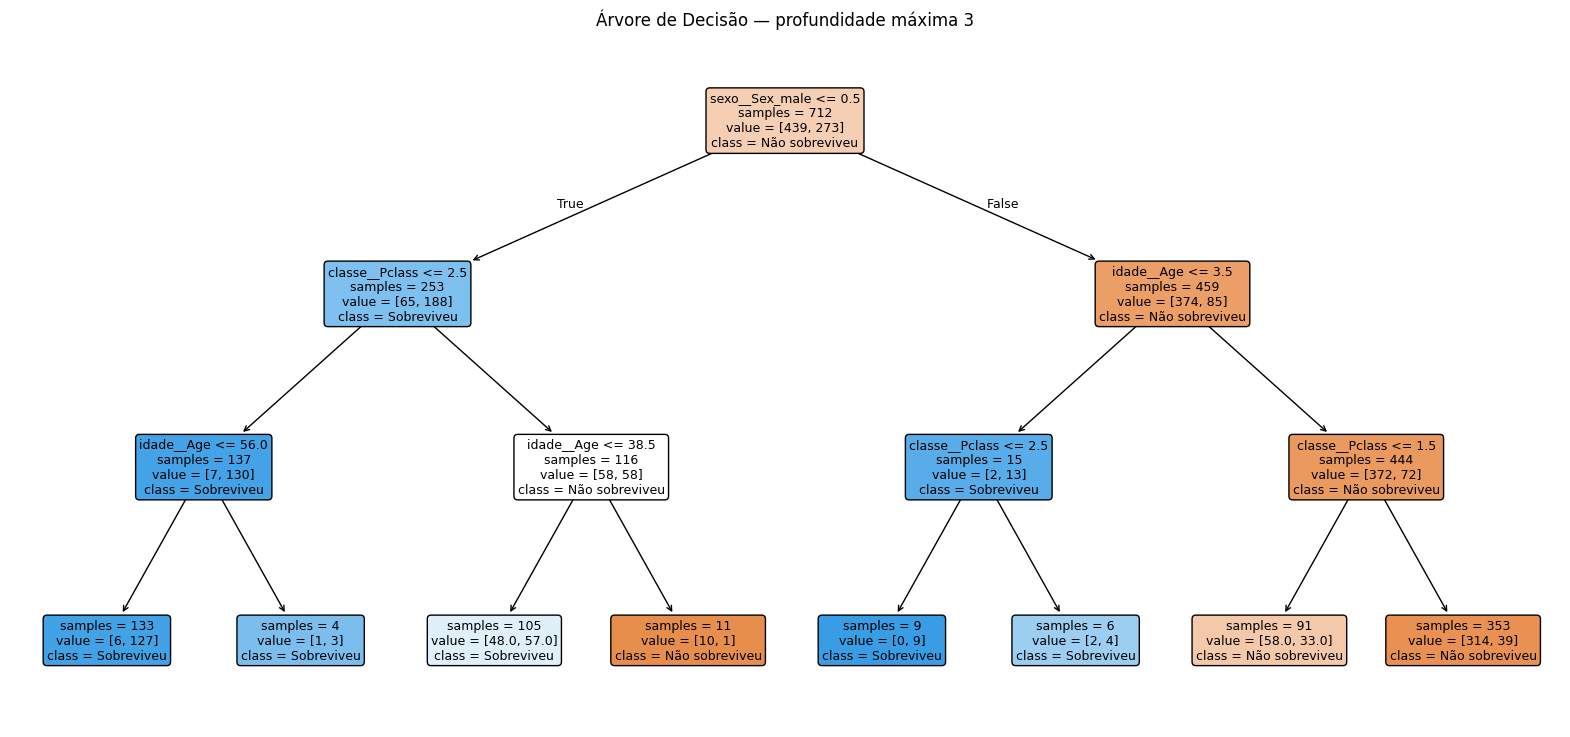

In [37]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Treina o pipeline com os 712 passageiros do treino
pipeline_arvore.fit(X_treino, y_treino)

# Recupera os nomes das entradas após a preparação
nomes_colunas = (
    pipeline_arvore.named_steps["preparacao"].get_feature_names_out()
)

plt.figure(figsize=(20, 9))

plot_tree(
    pipeline_arvore.named_steps["modelo"],
    feature_names=nomes_colunas,
    class_names=["Não sobreviveu", "Sobreviveu"],
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=9
)

plt.title("Árvore de Decisão — profundidade máxima 3")
plt.show()

In [38]:
personagem = pd.DataFrame({
    "Pclass": [2],
    "Sex": ["male"],
    "Age": [25]
})

chance = pipeline_arvore.predict_proba(personagem)[0, 1]

print(f"Sobrevivência estimada pela árvore: {chance:.1%}")

Sobrevivência estimada pela árvore: 11.0%


In [39]:
comparacao_brier = []

for nome, pipeline in [
    ("Regressão Logística", pipeline_logistica),
    ("Árvore — profundidade 3", pipeline_arvore)
]:
    resultados = cross_val_score(
        pipeline,
        X_treino,
        y_treino,
        cv=validacao,
        scoring="neg_brier_score"
    )

    comparacao_brier.append({
        "Modelo": nome,
        "Brier médio": -resultados.mean()
    })

pd.DataFrame(comparacao_brier).round(4)

,Modelo,Brier médio
0,Regressão Logística,0.1429
1,Árvore — profundidade 3,0.1327


Antes de escolhermos a versão final, vamos investigar aquelas folhas com poucos passageiros. Podemos exigir pelo menos 20 exemplos de treino em cada folha, usando min_samples_leaf=20. Isso pode reduzir estimativas extremas baseadas em grupos pequenos, mas precisamos verificar o resultado.

In [40]:
# Cria uma nova versão sem alterar a árvore anterior
pipeline_arvore_20 = clone(pipeline_arvore)

pipeline_arvore_20.set_params(
    modelo__min_samples_leaf=20
)

avaliacao_arvore_20 = cross_validate(
    pipeline_arvore_20,
    X_treino,
    y_treino,
    cv=validacao,
    scoring={
        "acuracia": "accuracy",
        "brier": "neg_brier_score"
    }
)

print(
    f"Acurácia média: "
    f"{avaliacao_arvore_20['test_acuracia'].mean():.1%}"
)
print(
    f"Brier médio: "
    f"{-avaliacao_arvore_20['test_brier'].mean():.4f}"
)

Acurácia média: 79.2%
Brier médio: 0.1407


Exigir 20 passageiros por folha piorou os dois resultados nesta validação.

Isso ilustra uma ideia importante: limitar a complexidade pode ajudar a evitar sobreajuste, mas limitar demais também pode impedir o aprendizado de padrões úteis. Neste experimento, a restrição não trouxe melhora.

Vamos manter a árvore original como candidata, sem declarar suas probabilidades perfeitamente calibradas.

In [41]:
from sklearn.model_selection import cross_val_predict

probabilidades_validacao = cross_val_predict(
    pipeline_arvore,
    X_treino,
    y_treino,
    cv=validacao,
    method="predict_proba"
)[:, 1]

print("Probabilidades geradas:", len(probabilidades_validacao))

Probabilidades geradas: 712


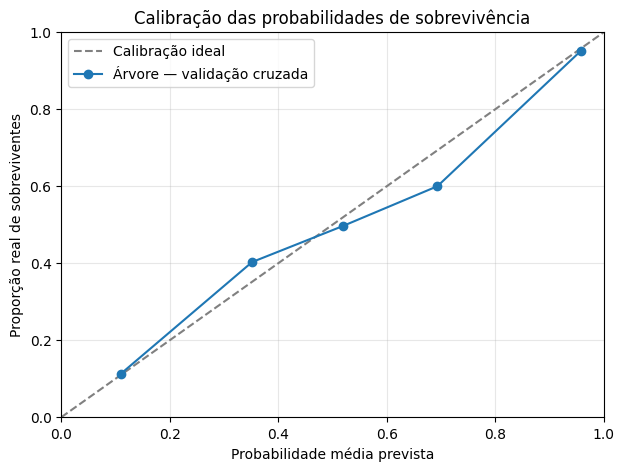

In [42]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

taxa_observada, probabilidade_media = calibration_curve(
    y_treino,
    probabilidades_validacao,
    n_bins=5,
    strategy="uniform"
)

plt.figure(figsize=(7, 5))

plt.plot([0, 1], [0, 1], "--", color="gray", label="Calibração ideal")
plt.plot(
    probabilidade_media,
    taxa_observada,
    marker="o",
    label="Árvore — validação cruzada"
)

plt.xlabel("Probabilidade média prevista")
plt.ylabel("Proporção real de sobreviventes")
plt.title("Calibração das probabilidades de sobrevivência")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [43]:
import numpy as np

diagnostico = pd.DataFrame({
    "probabilidade": probabilidades_validacao,
    "sobreviveu": y_treino.to_numpy()
})

# Usa os mesmos limites do gráfico de calibração
limites = np.linspace(0, 1, 6)

diagnostico["faixa"] = pd.cut(
    diagnostico["probabilidade"],
    bins=limites,
    include_lowest=True
)

resumo_calibracao = diagnostico.groupby(
    "faixa", observed=True
).agg(
    passageiros=("sobreviveu", "size"),
    probabilidade_media=("probabilidade", "mean"),
    taxa_observada=("sobreviveu", "mean")
)

resumo_calibracao

,passageiros,probabilidade_media,taxa_observada
faixa,,,
"(-0.001, 0.2]",364,0.109620,0.112637
"(0.2, 0.4]",67,0.351680,0.402985
"(0.4, 0.6]",133,0.518413,0.496241
"(0.6, 0.8]",5,0.693333,0.600000
"(0.8, 1.0]",143,0.957359,0.951049


A análise de calibração com previsões de validação cruzada mostrou proximidade entre probabilidades médias e frequências observadas nos grupos mais numerosos. A faixa de 60% a 80% apresentou apenas cinco passageiros, limitando sua interpretação. Esses resultados são diagnósticos de desenvolvimento, pois a mesma validação foi utilizada na comparação dos modelos.

In [44]:
from sklearn.metrics import accuracy_score, brier_score_loss

# Ajusta a preparação e o modelo somente com o treino
pipeline_arvore.fit(X_treino, y_treino)

previsoes_arvore_teste = pipeline_arvore.predict(X_teste)
probabilidades_arvore_teste = pipeline_arvore.predict_proba(X_teste)[:, 1]

print(
    f"Acurácia no teste: "
    f"{accuracy_score(y_teste, previsoes_arvore_teste):.1%}"
)
print(
    f"Brier no teste: "
    f"{brier_score_loss(y_teste, probabilidades_arvore_teste):.4f}"
)

Acurácia no teste: 76.5%
Brier no teste: 0.1581


In [45]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

matriz_arvore = confusion_matrix(
    y_teste, previsoes_arvore_teste, labels=[0, 1]
)

display(pd.DataFrame(
    matriz_arvore,
    index=["Real: não sobreviveu", "Real: sobreviveu"],
    columns=["Previsto: não sobreviveu", "Previsto: sobreviveu"]
))

print(
    f"Precisão para sobrevivência: "
    f"{precision_score(y_teste, previsoes_arvore_teste):.1%}"
)
print(
    f"Recall para sobrevivência: "
    f"{recall_score(y_teste, previsoes_arvore_teste):.1%}"
)

,Previsto: não sobreviveu,Previsto: sobreviveu
Real: não sobreviveu,92,18
Real: sobreviveu,24,45


Precisão para sobrevivência: 71.4%
Recall para sobrevivência: 65.2%


In [46]:
# Exibe as etapas de tratamento dos dados
display(preparacao)

ColumnTransformer(transformers=[('idade', SimpleImputer(strategy='median'),
                                 ['Age']),
                                ('sexo', OneHotEncoder(drop='if_binary'),
                                 ['Sex']),
                                ('classe', 'passthrough', ['Pclass'])])

In [47]:
print(preparacao)

ColumnTransformer(transformers=[('idade', SimpleImputer(strategy='median'),
                                 ['Age']),
                                ('sexo', OneHotEncoder(drop='if_binary'),
                                 ['Sex']),
                                ('classe', 'passthrough', ['Pclass'])])


In [48]:
# Características do passageiro fictício
passageiro = pd.DataFrame({
    "Pclass": [2],      # 1 = primeira, 2 = segunda, 3 = terceira classe
    "Sex": ["male"],    # "male" ou "female", conforme a base
    "Age": [38]
})

# Usa o pipeline já treinado
previsao = pipeline_arvore.predict(passageiro)[0]

# Localiza a coluna correspondente à classe 1: sobreviveu
indice_sobreviveu = list(pipeline_arvore.classes_).index(1)
probabilidade = pipeline_arvore.predict_proba(passageiro)[0, indice_sobreviveu]

resultado = "Sobreviveu" if previsao == 1 else "Não sobreviveu"

print(f"Classificação prevista: {resultado}")
print(f"Probabilidade estimada pelo modelo: {probabilidade:.1%}")

Classificação prevista: Não sobreviveu
Probabilidade estimada pelo modelo: 11.0%


In [49]:
# Características do passageiro fictício2
passageiro = pd.DataFrame({
    "Pclass": [1],      # 1 = primeira, 2 = segunda, 3 = terceira classe
    "Sex": ["male"],    # "male" ou "female", conforme a base
    "Age": [38]
})

# Usa o pipeline já treinado
previsao = pipeline_arvore.predict(passageiro)[0]

# Localiza a coluna correspondente à classe 1: sobreviveu
indice_sobreviveu = list(pipeline_arvore.classes_).index(1)
probabilidade = pipeline_arvore.predict_proba(passageiro)[0, indice_sobreviveu]

resultado = "Sobreviveu" if previsao == 1 else "Não sobreviveu"

print(f"Classificação prevista: {resultado}")
print(f"Probabilidade estimada pelo modelo: {probabilidade:.1%}")

Classificação prevista: Não sobreviveu
Probabilidade estimada pelo modelo: 36.3%


In [50]:
# Características do passageiro fictício3
passageiro = pd.DataFrame({
    "Pclass": [1],      # 1 = primeira, 2 = segunda, 3 = terceira classe
    "Sex": ["female"],    # "male" ou "female", conforme a base
    "Age": [38]
})

# Usa o pipeline já treinado
previsao = pipeline_arvore.predict(passageiro)[0]

# Localiza a coluna correspondente à classe 1: sobreviveu
indice_sobreviveu = list(pipeline_arvore.classes_).index(1)
probabilidade = pipeline_arvore.predict_proba(passageiro)[0, indice_sobreviveu]

resultado = "Sobreviveu" if previsao == 1 else "Não sobreviveu"

print(f"Classificação prevista: {resultado}")
print(f"Probabilidade estimada pelo modelo: {probabilidade:.1%}")

Classificação prevista: Sobreviveu
Probabilidade estimada pelo modelo: 95.5%


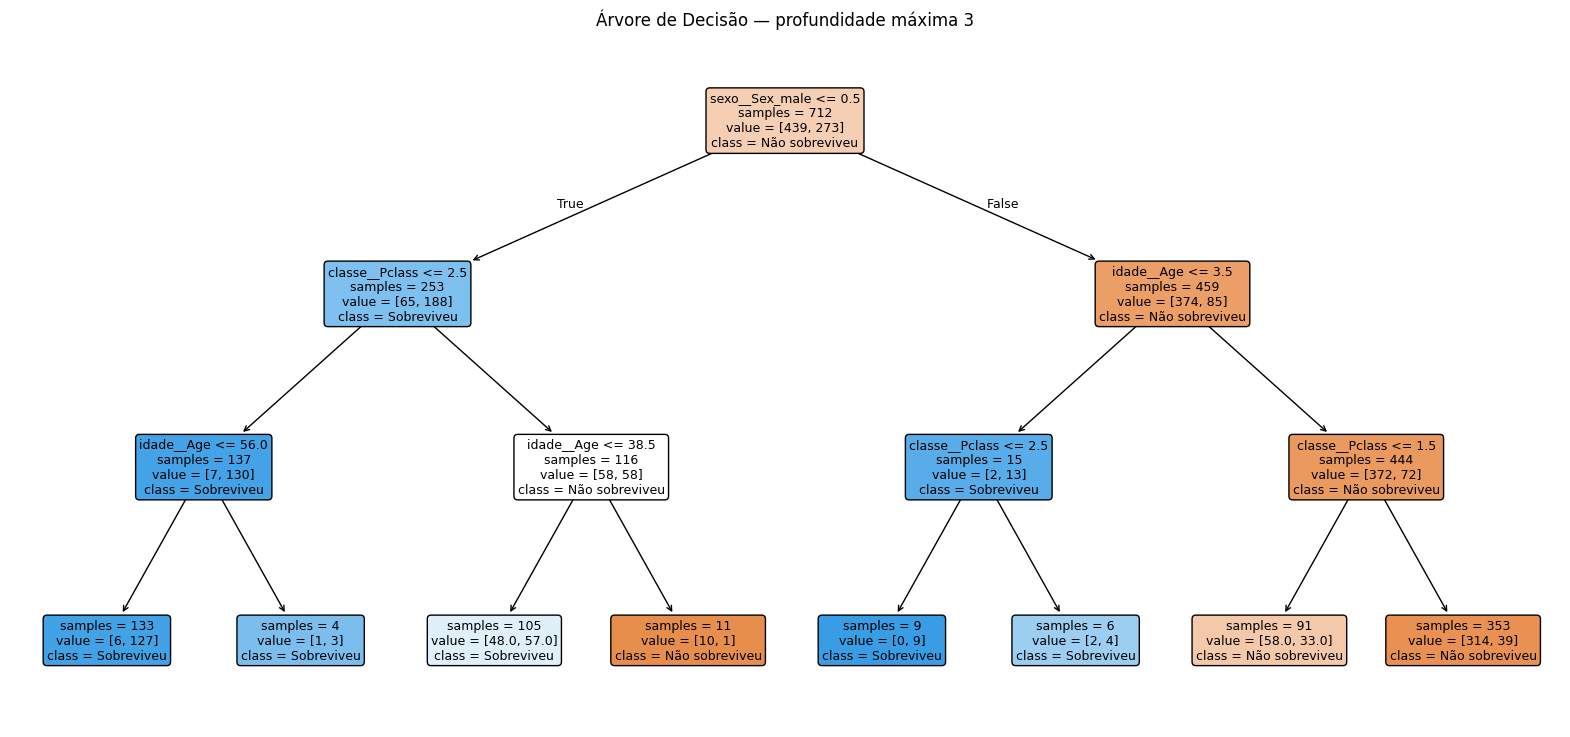

In [52]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Recupera os nomes das entradas após a preparação
nomes_colunas = (
    pipeline_arvore.named_steps["preparacao"].get_feature_names_out()
)

plt.figure(figsize=(20, 9))

plot_tree(
    pipeline_arvore.named_steps["modelo"],
    feature_names=nomes_colunas,
    class_names=["Não sobreviveu", "Sobreviveu"],
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=9
)

plt.title("Árvore de Decisão — profundidade máxima 3")
plt.show()

A árvore de decisão utiliza sexo, idade e classe para formar grupos de passageiros. As probabilidades previstas correspondem à proporção de sobreviventes em cada folha do conjunto de treinamento. O modelo alcançou 81,2% de acurácia média na validação cruzada e 76,5% no teste. Suas estimativas têm finalidade educativa e exigem cautela, especialmente em folhas com poucos passageiros.

O resultado é defensável porque:
- atingiu 76,5% de acurácia no teste, contra aproximadamente 61,5% do baseline;
- alcançou 81,2% de acurácia média na validação cruzada;
- utilizou dados de teste separados do treinamento;
- incorporou o tratamento de valores ausentes ao pipeline;
- comparou regressão logística e árvore de decisão;
- apresenta métricas além da acurácia: precisão, recall, matriz de confusão e Brier Score;
- produz previsões explicáveis por meio da visualização da árvore.

